Default rate aktual di test: 0.0668

Logit
  AUC=0.8540  Gini=0.7080  KS=0.5480
  rata-rata PD=0.0660
  cutoff=0.14 | precision=0.361 recall=0.539 | ditandai=10.0% dari peminjam
  biaya=4,905 vs setujui semua=7,520 (hemat 34.8%)

XGB
  AUC=0.8613  Gini=0.7226  KS=0.5699
  rata-rata PD=0.0659
  cutoff=0.158 | precision=0.354 recall=0.570 | ditandai=10.8% dari peminjam
  biaya=4,799 vs setujui semua=7,520 (hemat 36.2%)



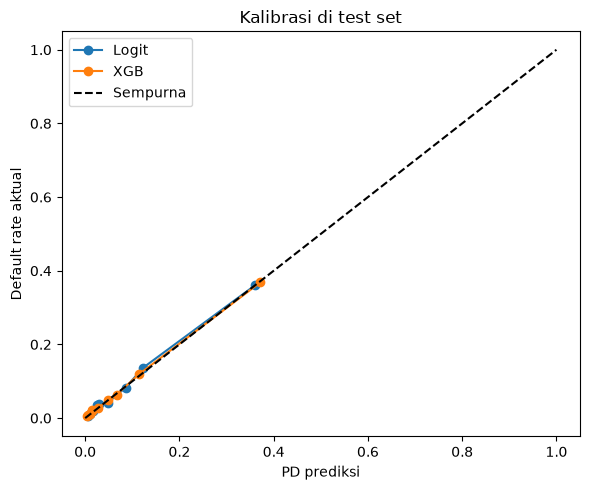

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score
from sklearn.calibration import calibration_curve

target = "SeriousDlqin2yrs"
te = pd.read_csv("../data/clean/test_clean.csv")
X_te, y_te = te.drop(columns=target), te[target].values

logit = joblib.load("../models/logit.joblib")
xgb = joblib.load("../models/xgb.joblib")
iso_logit = joblib.load("../models/iso_logit.joblib")
iso_xgb = joblib.load("../models/iso_xgb.joblib")

p = {
    "Logit": iso_logit.predict(logit.predict_proba(X_te)[:, 1]),
    "XGB": iso_xgb.predict(xgb.predict_proba(X_te)[:, 1]),
}
cutoffs = {"Logit": 0.140, "XGB": 0.158}
RATIO = 5

print("Default rate aktual di test:", round(y_te.mean(), 4))
print()
for name, pr in p.items():
    auc = roc_auc_score(y_te, pr)
    fpr, tpr, _ = roc_curve(y_te, pr)
    pred = pr >= cutoffs[name]
    fn = ((~pred) & (y_te == 1)).sum()
    fp = (pred & (y_te == 0)).sum()
    cost = RATIO * fn + fp
    base = RATIO * (y_te == 1).sum()
    print(f"{name}")
    print(f"  AUC={auc:.4f}  Gini={2*auc-1:.4f}  KS={np.max(tpr-fpr):.4f}")
    print(f"  rata-rata PD={pr.mean():.4f}")
    print(f"  cutoff={cutoffs[name]} | precision={precision_score(y_te, pred):.3f} "
          f"recall={recall_score(y_te, pred):.3f} | ditandai={pred.mean():.1%} dari peminjam")
    print(f"  biaya={cost:,} vs setujui semua={base:,} (hemat {1 - cost/base:.1%})")
    print()

fig, ax = plt.subplots(figsize=(6, 5))
for name, pr in p.items():
    frac, mean_p = calibration_curve(y_te, pr, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", label="Sempurna")
ax.set_title("Kalibrasi di test set")
ax.set_xlabel("PD prediksi")
ax.set_ylabel("Default rate aktual")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/calibration_test.png", dpi=150, bbox_inches="tight")
plt.show()